# Online Retail II Customer Segmentation Dataset


Objective:

To segment the online store's customers based on their purchasing behavior and identify the most valuable customers.

**About Dataset**

**Context**

This dataset contains transactional data from an online retail business and is prepared for customer behavior analysis, customer segmentation, and machine learning research in marketing analytics.

The dataset is designed to support customer grouping based on purchasing behavior for advertising and personalized marketing strategies. It is particularly suitable for clustering techniques and RFM-based customer analytics.

This dataset can be used in research areas such as:

- Customer Segmentation
- Marketing Analytics
- Behavioral Analysis
- Advertising Targeting
- CRM Analytics
- Clustering and Unsupervised Learning
- Dataset Overview

**The dataset includes customer transaction records such as:**

- Purchase history
- Product quantity
- Transaction dates
- Spending information
- Customer identifiers

These transactional records can be transformed into behavioral features for segmentation and machine learning tasks.


**Data Cleaning and Preprocessing**

The dataset has been prepared for analytical and machine learning purposes through several preprocessing steps:

- Removed cancelled transactions
- Removed missing customer identifiers
- Removed invalid or negative quantities
- Filtered abnormal pricing records
- Standardized transactional information
- Aggregated customer-level behavioral features

**Engineered Features**

To support customer segmentation and clustering tasks, several behavioral features were generated.

**RFM Features**

Feature	//  Description

 Recency //  Number of days since the customer's last purchase

 Frequency //	Total number of purchases made by the customer
 
 Monetary //	Total amount spent by the customer

## 1. Data Collection and Preparations

In [2]:
#Required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [3]:
data=pd.read_csv('online_retail_II_2010_2011.csv')
data

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,09/12/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,09/12/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,09/12/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,09/12/2011 12:50,4.95,12680.0,France


## 2. Verifying and Cleaning Data

In [4]:
data.shape

(541910, 8)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  str    
 1   StockCode    541910 non-null  str    
 2   Description  540456 non-null  str    
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  str    
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [6]:
#Check for empty cells
data.isnull().sum()

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

In [7]:
data.describe()

,Quantity,Price,Customer ID
count,541910.000000,541910.000000,406830.000000
mean,9.552234,4.611138,15287.684160
std,218.080957,96.759765,1713.603074
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


Although the dataset description states that invalid and negative quantities were removed, exploratory analysis revealed remaining negative values in Quantity and Price. Additional validation and cleaning steps were performed before customer segmentation.

In [8]:
#Quantity
print("Negative Quantity:", (data['Quantity'] < 0).sum())
negative_qty=(data['Quantity'] < 0).sum()
percentage_qty= negative_qty / len(data) * 100
print(f'Percentage of Negative Quantity: {percentage_qty:.2f}%') 

#Price
print("Negative Price:", (data['Price'] < 0).sum())
negative_price=(data['Price'] < 0).sum()
percentage_price= negative_price / len(data) * 100
print(f'Percentage of Negative Price: {percentage_price:.4f}%') 
print("Zero Price:", (data['Price'] == 0).sum())

#Customer ID
print("Missing Customer ID:", data['Customer ID'].isna().sum())
missing_customer=data['Customer ID'].isna().sum()
percentage_mis_cust=missing_customer/len(data)*100
print(f'Percentage of Missing Customer ID: {percentage_mis_cust:.2f}%')

#Duplicates
print("Duplicates:", data.duplicated().sum())
duplicates=data.duplicated().sum()
percentage_dupl=duplicates/len(data)*100
print(f'Percentage of Duplicates: {percentage_dupl:.2f}%')

Negative Quantity: 10624
Percentage of Negative Quantity: 1.96%
Negative Price: 2
Percentage of Negative Price: 0.0004%
Zero Price: 2515
Missing Customer ID: 135080
Percentage of Missing Customer ID: 24.93%
Duplicates: 5268
Percentage of Duplicates: 0.97%


The dataset contains returns (1.96% negative quantities), a small number of negative prices, 24.93% missing customer identifiers, and 0.97% duplicate records. Data cleaning was performed before further analysis and customer segmentation.

In [9]:
print('Original dataset shape:', data.shape)

Original dataset shape: (541910, 8)


In [10]:
#Removing Negative Quantities (cancelled transactions)
data=data[data['Quantity']>0]
print('After removing negative quantities:', data.shape)

After removing negative quantities: (531286, 8)


In [11]:
#Removing Negative Prices and Zero price
data=data[data['Price']>0]
print('After removing negative price and Zero price:', data.shape)

After removing negative price and Zero price: (530105, 8)


In [12]:
#Removing blank Customer ID fields
data=data.dropna(subset=['Customer ID'])
print('After removing missing Customer IDs:', data.shape)

After removing missing Customer IDs: (397885, 8)


In [13]:
#Removing Duplicates
data=data.drop_duplicates()
print('After removing duplicates:', data.shape)

After removing duplicates: (392693, 8)


Checking the result after cleaning:

In [14]:
data.describe()

,Quantity,Price,Customer ID
count,392693.000000,392693.000000,392693.000000
mean,13.119671,3.125952,15287.837224
std,180.492603,22.241820,1713.542421
min,1.000000,0.001000,12346.000000
25%,2.000000,1.250000,13955.000000
50%,6.000000,1.950000,15150.000000
75%,12.000000,3.750000,16791.000000
max,80995.000000,8142.750000,18287.000000


In [15]:
data.info()

<class 'pandas.DataFrame'>
Index: 392693 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      392693 non-null  str    
 1   StockCode    392693 non-null  str    
 2   Description  392693 non-null  str    
 3   Quantity     392693 non-null  int64  
 4   InvoiceDate  392693 non-null  str    
 5   Price        392693 non-null  float64
 6   Customer ID  392693 non-null  float64
 7   Country      392693 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 27.0 MB


To ensure reliable customer segmentation, the following cleaning steps were performed:

- Removed transactions with negative quantities (returns and cancellations).
- Removed records with negative and zero prices.
- Removed rows with missing Customer IDs.
- Removed duplicate transactions.

After cleaning, the dataset contained only valid customer purchase records suitable for RFM analysis and clustering.

## 3. Engineered Features

To support customer segmentation and clustering analysis, a new feature called **Revenue** was created by multiplying the purchased quantity by the unit price. 

This feature represents the monetary value of each transaction and will be used later in the RFM analysis

In [16]:
data['Revenue']=data['Quantity']*data['Price']

In [17]:
data[['Quantity', 'Price', 'Revenue']].head()

,Quantity,Price,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [18]:
#Verify that the Revenue feature was created correctly.
data['Revenue'].describe()

count    392693.000000
mean         22.631488
std         311.098828
min           0.001000
25%           4.950000
50%          12.450000
75%          19.800000
max      168469.600000
Name: Revenue, dtype: float64

## 4. Exploratory Data Analysis (EDA)

In [19]:
#Top 10 Countries by Revenue
top_countries = data.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)

top_countries

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208952.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

C:\Users\HannaBudzko\AppData\Local\Temp\ipykernel_1668\2206098319.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


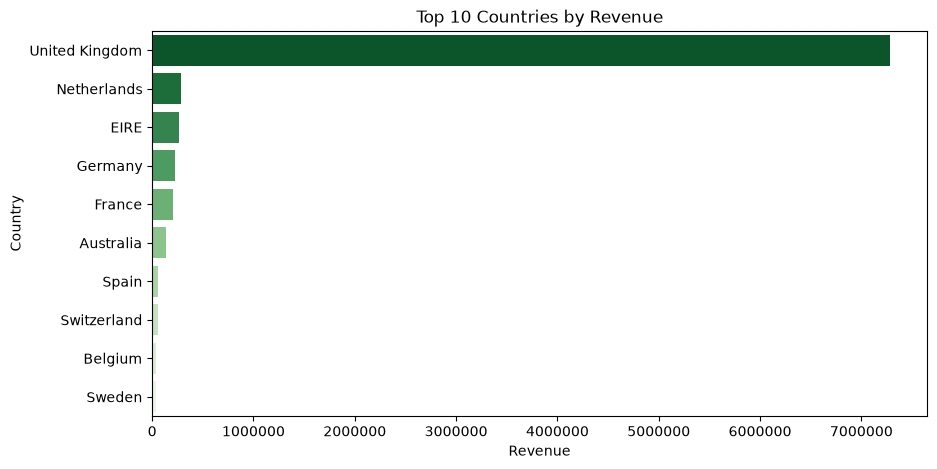

In [20]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    palette='Greens_r'
)

plt.ticklabel_format(style='plain', axis='x')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Country')

plt.show()

In [21]:
#Top 10 Clients by Revenue
top_customers = (
    data.groupby('Customer ID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

Customer ID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

C:\Users\HannaBudzko\AppData\Local\Temp\ipykernel_1668\3991532666.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


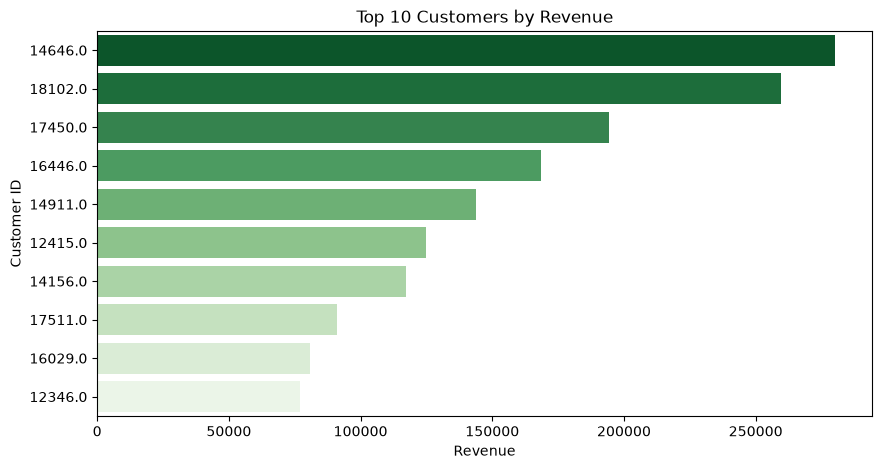

In [22]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=top_customers.values,
    y=top_customers.index.astype(str),
    palette='Greens_r'
)

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Customer ID')

plt.show()

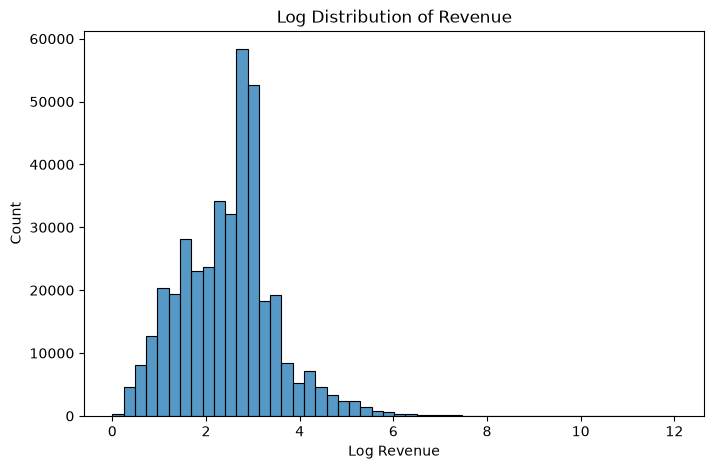

In [23]:
plt.figure(figsize=(8,5))

sns.histplot(
    np.log1p(data['Revenue']),
    bins=50
)

plt.title('Log Distribution of Revenue')
plt.xlabel('Log Revenue')
plt.ylabel('Count')

plt.show()

The Revenue distribution is highly right-skewed. Most transactions have relatively low revenue values, while a small number of transactions generate exceptionally high revenue. This long-tail pattern is common in retail datasets.

## 5. RFM Analysis

- R = Recency
- F = Frequency
- M = Monetary

In [24]:
data['InvoiceDate'] = pd.to_datetime(
    data['InvoiceDate'],
    dayfirst=True
)

In [25]:
data['InvoiceDate'].dtype

dtype('<M8[us]')

In [26]:
#Create a reference date for Recency calculation.
snapshot_date = data['InvoiceDate'].max() + pd.Timedelta(days=1)
snapshot_date

Timestamp('2011-12-10 12:50:00')

In [27]:
#Creating an RFM table
rfm = data.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'Invoice': 'nunique',
    'Revenue': 'sum'
})
rfm.head()

,InvoiceDate,Invoice,Revenue
Customer ID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [28]:
#Renaming Columns
rfm.columns = ['Recency', 'Frequency', 'Monetary']
rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


RFM metrics were calculated for each customer:

- **Recency**: number of days since the last purchase.
- **Frequency**: number of unique invoices.
- **Monetary**: total revenue generated by the customer.

These metrics provide a compact summary of customer purchasing behavior and will be used for segmentation.

In [29]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.692230
std,100.014169,7.697998,8985.229676
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


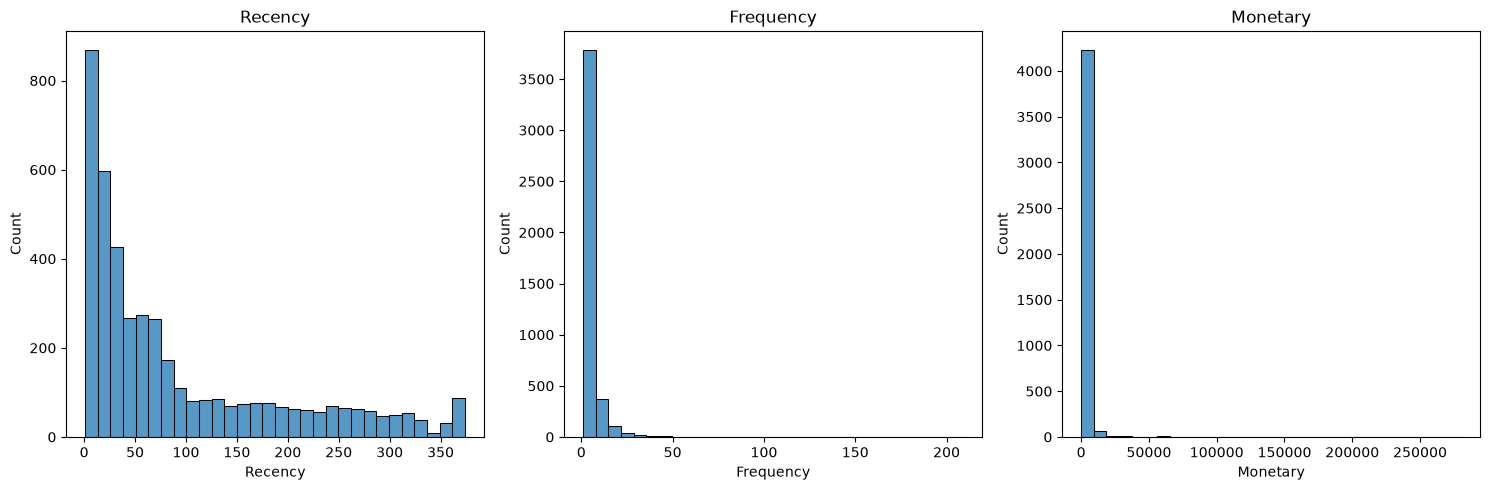

In [30]:
#checking the distributions
fig, axes = plt.subplots(1,3, figsize=(15,5))

sns.histplot(rfm['Recency'], bins=30, ax=axes[0])
axes[0].set_title('Recency')

sns.histplot(rfm['Frequency'], bins=30, ax=axes[1])
axes[1].set_title('Frequency')

sns.histplot(rfm['Monetary'], bins=30, ax=axes[2])
axes[2].set_title('Monetary')

plt.tight_layout()
plt.show()

**Recency** is slightly skewed to the right, but looks  normal. 

**Frequency**: Most customers have 1–5 purchases, but there are customers with 50+, 100+, and 200 purchases.  There is a clear long tail to the right.

**Monetary**:  There is a significant skew. Most customers spent < 2,000, but there are customers who spent 50,000+, 100,000+, and 280,000+. 

This is a problem for K-Means because the algorithm uses distances, and such extreme values begin to dominate.



In [31]:
# Reduce skewness in Frequency and Monetary.
rfm['Frequency'] = np.log1p(rfm['Frequency'])
rfm['Monetary'] = np.log1p(rfm['Monetary'])

Handling Skewed Features

The Frequency and Monetary variables showed highly right-skewed distributions due to a small number of customers with exceptionally high purchase activity and spending.

To reduce the impact of outliers and improve clustering performance, a logarithmic transformation was applied to both variables.

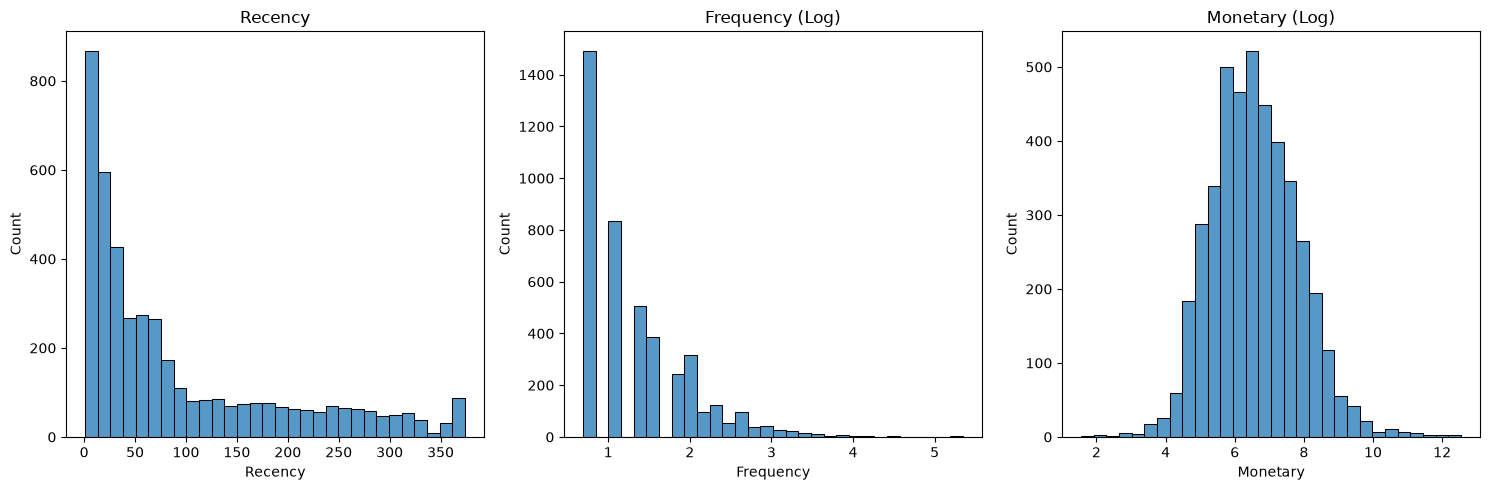

In [32]:
#Verification After Logarithm Computation
fig, axes = plt.subplots(1,3, figsize=(15,5))

sns.histplot(rfm['Recency'], bins=30, ax=axes[0])
axes[0].set_title('Recency')

sns.histplot(rfm['Frequency'], bins=30, ax=axes[1])
axes[1].set_title('Frequency (Log)')

sns.histplot(rfm['Monetary'], bins=30, ax=axes[2])
axes[2].set_title('Monetary (Log)')

plt.tight_layout()
plt.show()

In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)

In [34]:
rfm_scaled

array([[ 2.33457414, -0.95521426,  3.70771049],
       [-0.90534032,  1.07442519,  1.41489888],
       [-0.17535959,  0.38630445,  0.72002011],
       ...,
       [-0.8453419 , -0.36158278, -1.11333475],
       [-0.88534085,  2.17800394,  0.82280794],
       [-0.49535114,  0.05960547,  0.73752154]], shape=(4338, 3))

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)
rfm_scaled.shape

(4338, 3)

## 6.  Finding the Optimal Number of Clusters

Use the Elbow Method to identify the optimal number of clusters.

In [36]:
from sklearn.cluster import KMeans

# Calculate WCSS for different numbers of clusters.
wcss = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    wcss.append(kmeans.inertia_)

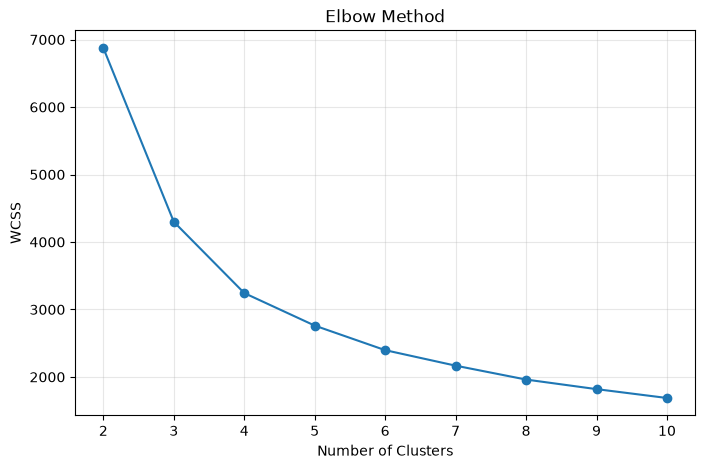

In [37]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    wcss,
    marker='o'
)

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')

plt.grid(alpha=0.3)

plt.show()

**Selecting the Number of Clusters**

The Elbow Method suggests that the optimal number of clusters is around 5. After this point, additional clusters provide only marginal reductions in WCSS.

Therefore, k = 5 was selected for customer segmentation

## 7. Model Building

In [38]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

In [39]:
#Segment Dimensions

rfm['Cluster'].value_counts().sort_index()

Cluster
0    1203
1     896
2     324
3     958
4     957
Name: count, dtype: int64

In [40]:
#Cluster Analysis (Average values)
cluster_summary = rfm.groupby('Cluster').mean()
cluster_summary

,Recency,Frequency,Monetary
Cluster,,,
0,60.911887,1.272137,6.714510
1,263.505580,0.818048,5.618210
2,14.725309,2.930961,8.983742
3,58.535491,0.803215,5.435808
4,32.598746,1.938007,7.681813


In [41]:
segment_names = {
    0: 'Regular Customers',
    1: 'Lost Customers',
    2: 'VIP Customers',
    3: 'Low-Value Customers',
    4: 'Loyal Customers'
}

rfm['Segment'] = rfm['Cluster'].map(segment_names)

In [42]:
rfm['Segment'].value_counts()

Segment
Regular Customers      1203
Low-Value Customers     958
Loyal Customers         957
Lost Customers          896
VIP Customers           324
Name: count, dtype: int64

In [43]:
rfm.head()

,Recency,Frequency,Monetary,Cluster,Segment
Customer ID,,,,,
12346.0,326,0.693147,11.253955,4,Loyal Customers
12347.0,2,2.079442,8.368925,4,Loyal Customers
12348.0,75,1.609438,7.494564,4,Loyal Customers
12349.0,19,0.693147,7.472245,0,Regular Customers
12350.0,310,0.693147,5.815324,1,Lost Customers


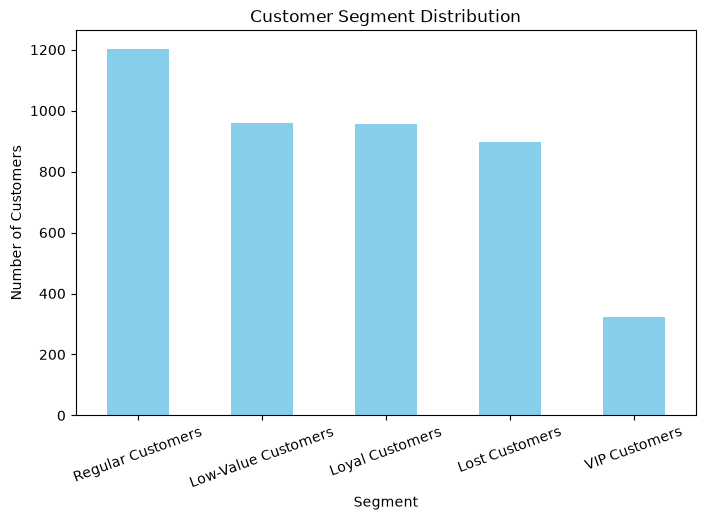

In [44]:
plt.figure(figsize=(8,5))

rfm['Segment'].value_counts().plot(
    kind='bar',
    color='skyblue'
)

plt.title('Customer Segment Distribution')
plt.xlabel('Segment')
plt.ylabel('Number of Customers')

plt.xticks(rotation=20)

plt.show()

## 8. Business Insights:
- **Cluster 2** (VIP Customers): Lowest Recency (14.7), highest Frequency (2.93) and Monetary value (8.98). These are the most valuable customers.
- **Cluster 4** (Loyal Customers): Relatively recent purchases (32.6) with high spending levels (7.68). Strong candidates for loyalty programs.
- **Cluster 0** (Regular Customers): Moderate Recency (60.9), Frequency (1.27), and Monetary value (6.71). Represent a stable customer base.
- **Cluster 3** (Low-Value Customers): Low purchase frequency (0.80) and spending levels (5.44). Opportunities exist to increase engagement.
- **Cluster 1** (Lost Customers): Very high Recency (263.5), indicating customers who have not purchased for a long period and may require win-back marketing campaigns.

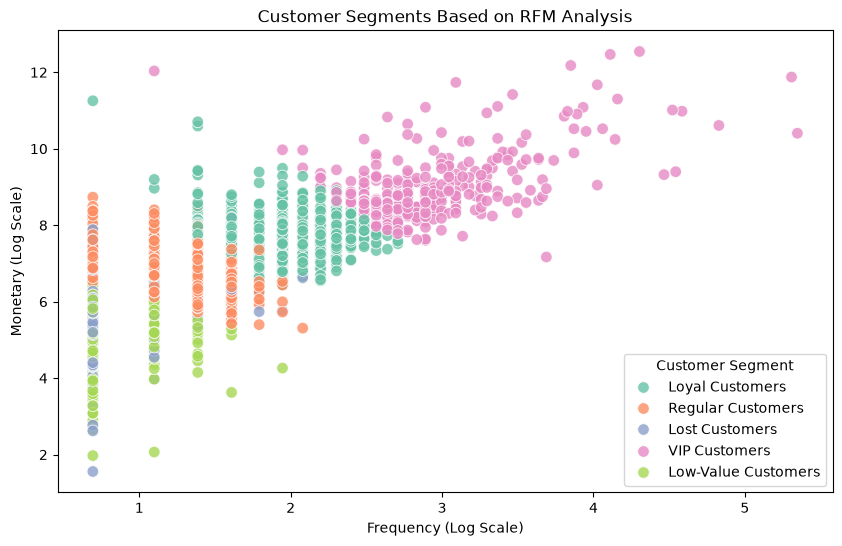

In [45]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Segment',
    palette='Set2',
    s=70,
    alpha=0.8
)

plt.title('Customer Segments Based on RFM Analysis')
plt.xlabel('Frequency (Log Scale)')
plt.ylabel('Monetary (Log Scale)')

plt.legend(title='Customer Segment')
plt.show()

## Conclusion

Five customer segments were identified based on purchasing behavior.

VIP Customers represent the most valuable group, while Lost Customers may require re-engagement strategies. The results demonstrate how RFM Analysis and K-Means Clustering can support customer-focused business decisions and marketing strategies.